# The reward-driven alerting policy (slice M2): how it was learned

A (1+30) evolution strategy with a reward, not deep or per-step reinforcement learning. Each generation draws 30
candidates around the current policy, picks the best on 8 selection trials, and accepts it only if it beats the
current policy on 12 fresh trials. All data are simulator trials. **Synthetic, not validated.**

This notebook only reads the run log (`training/runs/reward_policy/`), the committed generation records' ledger
(`experiments.jsonl`), the two policy files and `held_out.txt`, and draws them. It trains nothing, opens no trial and
computes no new held-out number.

In [1]:
# Finds the repository root (the folder that holds models/ and training/). This notebook only reads and draws.
import json
import logging
import re
from pathlib import Path

logging.getLogger("matplotlib").setLevel(logging.ERROR)
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "models").is_dir() and (p / "training").is_dir())
COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]  # Okabe-Ito
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 9})


def ints(*axes):
    """Whole numbers on the x axis (generations and epochs)."""
    for ax in axes:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))


def newest_log(model):
    """The run log with the newest file name under training/runs/<model>/ (the names carry the date)."""
    logs = sorted((ROOT / "training" / "runs" / model).glob("*.json"))
    return json.loads(logs[-1].read_text()), logs[-1].name


In [2]:
log, log_name = newest_log("reward_policy")
RP = ROOT / "models" / "tier_b" / "reward_policy"
ledger = [json.loads(line) for line in (RP / "experiments.jsonl").read_text().splitlines()]
assert [r["ledger"] for r in log["runs"]] == [x for x in ledger if x["decision"] != "stop"], "run log and ledger disagree"
runs = log["runs"]
print(f"run log {log_name}: run id {log['run_id']}, commit {log['commit']}")
print("framework:", log["framework"], "| time:", log["time"]["note"])
for r in runs:
    print(f"{r['name']}: {len(r['generations']) - 1} generations after generation 0, stopped by {r['ledger']['stop_reason']}")

run log m2-20261113.json: run id m2-20261113, commit 6c5814f
framework: none (six numbers, plain arithmetic) | time: no wall time: this log is built from committed records, no trial was opened
round 1: 5 generations after generation 0, stopped by patience
round 2: 3 generations after generation 0, stopped by patience
no temperature: 4 generations after generation 0, stopped by patience


## Validation reward per generation

The current policy after each generation, scored on the 60 validation trials (seeds 341-400). A policy that is in alert longer than the NEWS2 chart trigger on any trial is rejected and has no reward (a cross at the bottom).

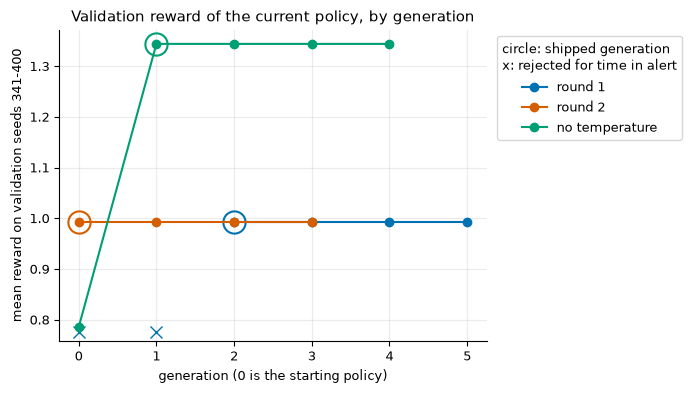

Reading: round 1 shipped generation 2 with validation reward 0.992414; generations rejected for time in alert: [0, 1].
Reading: round 2 shipped generation 0 with validation reward 0.992414; generations rejected for time in alert: none.
Reading: no temperature shipped generation 1 with validation reward 1.343958; generations rejected for time in alert: none.


In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for run, c in zip(runs, COLORS):
    gens = run["generations"]
    ax.plot([g["generation"] for g in gens], [float("nan") if g["validation_reward"] is None else g["validation_reward"] for g in gens],
            "-o", color=c, label=run["name"])
    bad = [g["generation"] for g in gens if g["validation_rejected"]]
    ax.plot(bad, [0.03] * len(bad), "x", color=c, ms=9, transform=ax.get_xaxis_transform())
    ship = run["ledger"]["shipped"]
    if ship:
        ax.plot(ship["generation"], ship["validation_reward"], "o", ms=16, mfc="none", mec=c, mew=1.5)
ax.set_title("Validation reward of the current policy, by generation")
ax.set_xlabel("generation (0 is the starting policy)")
ax.set_ylabel("mean reward on validation seeds 341-400")
ax.legend(title="circle: shipped generation\nx: rejected for time in alert", loc="upper left", bbox_to_anchor=(1.01, 1))
ints(ax)
fig.tight_layout()
plt.show()
for run in runs:
    ship = run["ledger"]["shipped"]
    rejected = [g["generation"] for g in run["generations"] if g["validation_rejected"]]
    print(f"Reading: {run['name']} shipped generation {ship['generation']} with validation reward {ship['validation_reward']}; "
          f"generations rejected for time in alert: {rejected or 'none'}.")

## Selection lead against the confirmation test

The winner of 30 candidates always looks good on the 8 selection trials. It is accepted only if its mean paired difference *d* from the current policy on 12 fresh trials is above the threshold (1.796 x standard deviation / sqrt(12)). Filled circle: accepted. Hollow circle: not accepted.

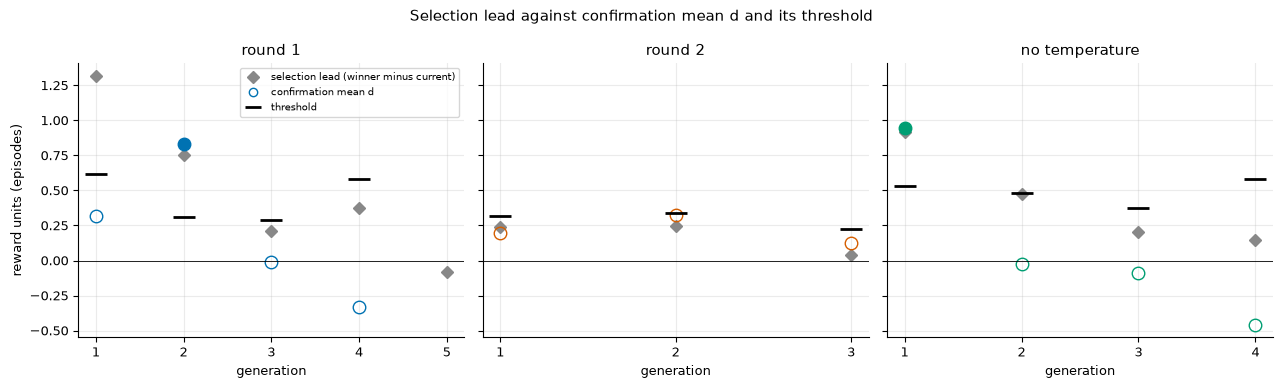

Reading: round 1: selection leads [1.32, 0.75, 0.21, 0.38]; confirmation mean d [0.319833, 0.830741, -0.010871, -0.334968]; accepted in generations [2].
Reading: round 2: selection leads [0.24, 0.24, 0.04]; confirmation mean d [0.196165, 0.327919, 0.123924]; accepted in generations none.
Reading: no temperature: selection leads [0.92, 0.47, 0.2, 0.15]; confirmation mean d [0.943192, -0.021926, -0.086718, -0.458387]; accepted in generations [1].


In [4]:
fig, axes = plt.subplots(1, len(runs), figsize=(4.3 * len(runs), 3.9), sharey=True)
for ax, run, c in zip(axes, runs, COLORS):
    gens = [g for g in run["generations"] if g["selection"] and g["selection"]["winner_mean"] is not None]
    lead = [g["selection"]["winner_mean"] - g["selection"]["current_mean"] for g in gens]
    ax.plot([g["generation"] for g in gens], lead, "D", color="#888888", label="selection lead (winner minus current)")
    conf = [g for g in gens if g["confirmation"]]
    for g in conf:
        ax.plot(g["generation"], g["confirmation"]["mean_d"], "o", ms=9, color=c, mfc=c if g["accepted"] else "none")
        ax.plot(g["generation"], g["confirmation"]["threshold"], "_", ms=16, mew=2, color="black")
    ax.plot([], [], "o", color=c, mfc="none", label="confirmation mean d")
    ax.plot([], [], "_", ms=12, mew=2, color="black", label="threshold")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(run["name"])
    ax.set_xlabel("generation")
    ints(ax)
axes[0].set_ylabel("reward units (episodes)")
axes[0].legend(fontsize=7)
fig.suptitle("Selection lead against confirmation mean d and its threshold")
fig.tight_layout()
plt.show()
for run in runs:
    conf = [g for g in run["generations"] if g["confirmation"]]
    acc = [g["generation"] for g in conf if g["accepted"]]
    leads = [round(g["selection"]["winner_mean"] - g["selection"]["current_mean"], 2) for g in conf]
    ds = [g["confirmation"]["mean_d"] for g in conf]
    print(f"Reading: {run['name']}: selection leads {leads}; confirmation mean d {ds}; accepted in generations {acc or 'none'}.")

## Candidates rejected for time in alert

Of the 30 candidates drawn in a generation, those that were in alert longer than the NEWS2 chart trigger on any selection trial are dropped before the winner is chosen.

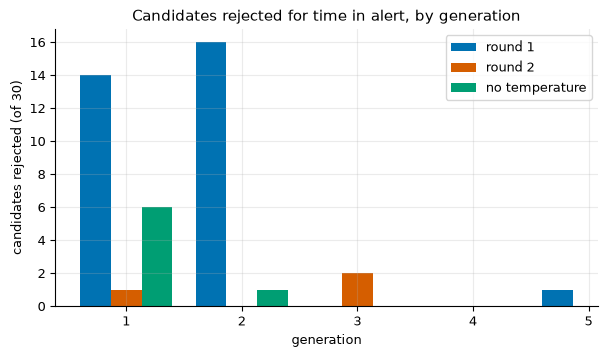

Reading: round 1: 31 of 150 candidates were rejected for time in alert ([14, 16, 0, 0, 1]).
Reading: round 2: 3 of 90 candidates were rejected for time in alert ([1, 0, 2]).
Reading: no temperature: 7 of 120 candidates were rejected for time in alert ([6, 1, 0, 0]).


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
w = 0.8 / len(runs)
for i, (run, c) in enumerate(zip(runs, COLORS)):
    gens = [g for g in run["generations"] if g["selection"]]
    ax.bar([g["generation"] + (i - (len(runs) - 1) / 2) * w for g in gens], [g["selection"]["candidates_rejected"] for g in gens],
           width=w, color=c, label=run["name"])
ax.set_title("Candidates rejected for time in alert, by generation")
ax.set_xlabel("generation")
ax.set_ylabel("candidates rejected (of 30)")
ints(ax)
ax.legend()
plt.show()
for run in runs:
    r = [g["selection"]["candidates_rejected"] for g in run["generations"] if g["selection"]]
    print(f"Reading: {run['name']}: {sum(r)} of {30 * len(r)} candidates were rejected for time in alert ({r}).")

## Step size sigma

The step size is kept after an accepted generation and shrunk (x 0.85) after one that accepts nothing, down to a floor. Solid: weights and theta. Dashed: persistence p (twice as large by design).

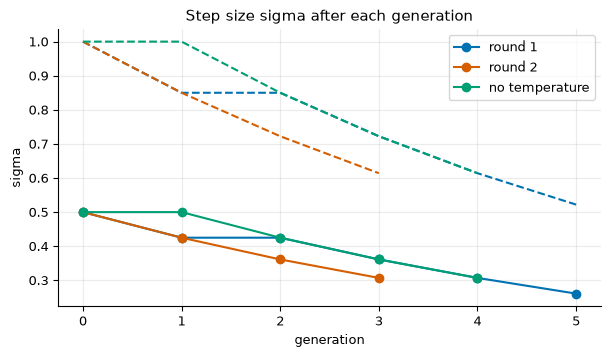

Reading: round 1: sigma for weights went from 0.5 to 0.261003125 over 5 generations.
Reading: round 2: sigma for weights went from 0.5 to 0.3070625 over 3 generations.
Reading: no temperature: sigma for weights went from 0.5 to 0.3070625 over 4 generations.


In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for run, c in zip(runs, COLORS):
    gens = run["generations"]
    ax.plot([g["generation"] for g in gens], [g["sigma_next"]["w"] for g in gens], "-o", color=c, label=run["name"])
    ax.plot([g["generation"] for g in gens], [g["sigma_next"]["p"] for g in gens], "--", color=c)
ax.set_title("Step size sigma after each generation")
ax.set_xlabel("generation")
ax.set_ylabel("sigma")
ints(ax)
ax.legend()
plt.show()
for run in runs:
    s = [g["sigma_next"]["w"] for g in run["generations"]]
    print(f"Reading: {run['name']}: sigma for weights went from {s[0]} to {s[-1]} over {len(s) - 1} generations.")

## The ledger

One line per round of the outer loop (a research agent proposes one change and says why; the change is kept only if the round's policy beats the incumbent on validation by 2 standard errors), then the stop line and the one-off no-temperature run.

In [7]:
def tried(x):
    if x["decision"] == "stop":
        return "stop the outer loop"
    if x["decision"] == "no_temperature":
        return "learn the no-temperature policy once (temperature weight fixed at 0)"
    return "baseline: the default configuration" if x["change"] is None else f"{x['change']['key']}: {x['change']['from']} to {x['change']['to']}"


def result(x):
    if x["decision"] == "stop":
        return "-"
    s = x["shipped"]
    text = f"shipped generation {s['generation']}, validation reward {s['validation_reward']}; {x['generations']} generations, stopped by {x['stop_reason']}"
    v = x.get("vs_incumbent")
    return text + (f"; vs incumbent mean {v['mean']}, margin {v['margin']}" if v else "")


names = {"baseline": "kept (the first incumbent)", "kept": "kept", "dropped": "dropped", "stop": "stop", "no_temperature": "kept (learned once)"}
rows = ["| round | what was tried | why | result | kept or dropped |", "|---|---|---|---|---|"]
for x in ledger:
    rows.append(f"| {x.get('round', '-')} | {tried(x)} | {(x.get('why') or x.get('reason') or '-').replace('|', '/')} | {result(x)} | {names[x['decision']]} |")
display(Markdown("\n".join(rows)))

| round | what was tried | why | result | kept or dropped |
|---|---|---|---|---|
| 1 | baseline: the default configuration | baseline: the default configuration | shipped generation 2, validation reward 0.992414; 5 generations, stopped by patience | kept (the first incumbent) |
| 2 | selection_trials: 8 to 16 | In round-1 gen-01, gen-03 and gen-04 the selection winner led the current policy on the 8 selection trials (+1.32, +0.21, +0.38) and its lead vanished on the 12 confirmation trials (mean d +0.32, -0.01, -0.33). This is the winner's-curse pattern; step size, a dead vital, the form and theta drift are not clearly supported by these records. 16 selection trials halve the selection variance so the winner sent to confirmation is more often truly better. | shipped generation 0, validation reward 0.992414; 3 generations, stopped by patience; vs incumbent mean 0.0, margin 0.0 | dropped |
| - | stop the outer loop | no change proposed: in round-2 gen-01 to gen-03 the winners were confirmed slightly better than the incumbent (mean d +0.20, +0.33, +0.12) but below their thresholds, which points to a plateau whose gains are near the 0.19 validation margin rather than to any menu key, as the round-2 proposal pre-registered. | - | stop |
| - | learn the no-temperature policy once (temperature weight fixed at 0) | - | shipped generation 1, validation reward 1.343958; 4 generations, stopped by patience | kept (learned once) |

## The shipped parameters

Six numbers: four non-negative weights, a threshold theta and a persistence p. A bin alerts when the weighted score is at least theta in p bins in a row.

In [8]:
rows = ["| file | heart rate | respiratory rate | SpO2 | temperature | theta | p | form | generation | validation reward |", "|---|---|---|---|---|---|---|---|---|---|"]
for name, path in (("policy.json (with temperature)", RP / "policy.json"), ("no_temperature/policy.json", RP / "no_temperature" / "policy.json")):
    p = json.loads(path.read_text())
    w = p["params"]["weights"]
    rows.append(f"| {name} | {w['heart_rate']} | {w['respiratory_rate']} | {w['spo2']} | {w['temperature']} | {p['params']['theta']} | "
                f"{p['params']['p']} | {p['config']['form']} | {p['chosen_generation']} | {p['validation_reward']} |")
display(Markdown("\n".join(rows)))

| file | heart rate | respiratory rate | SpO2 | temperature | theta | p | form | generation | validation reward |
|---|---|---|---|---|---|---|---|---|---|
| policy.json (with temperature) | 0.614 | 0.5247 | 1.0638 | 0.3149 | 2.9776 | 5 | sum | 2 | 0.992414 |
| no_temperature/policy.json | 0.3372 | 0.5534 | 1.2459 | 0.0 | 3.3703 | 3 | sum | 1 | 1.343958 |

## The held-out result, scored once

The held-out run (ward-v2 seeds 11-30) was made once, at the end, with `research.reward_loop --evaluate`. The next cell reads `held_out.txt` and prints the rows quoted below; the assertions fail if a quoted number is not in the file.

In [9]:
held = (RP / "held_out.txt").read_text()
COLS = ["news2_chart_trigger", "baseline_alone", "news2_or_baseline", "baseline_alone_no_temp", "news2_or_baseline_no_temp",
        "reward_gen0", "news2_or_reward_gen0", "reward_final", "news2_or_reward_final", "reward_gen0_no_temp",
        "news2_or_reward_gen0_no_temp", "reward_final_no_temp", "news2_or_reward_final_no_temp"]  # the file's header, in order
table, last = {}, None
for line in held.splitlines():
    parts = re.split(r"\s{2,}", line.strip())
    if len(parts) == len(COLS) + 1:
        label = parts[0] if not parts[0].startswith("95% interval") else f"{last} / {parts[0]}"
        table[label] = dict(zip(COLS, parts[1:]))
        if not parts[0].startswith("95% interval"):
            last = parts[0]
QUOTED = [
    ("alerts per patient per 12-hour shift", "news2_chart_trigger", "0.414"),
    ("alerts per patient per 12-hour shift", "reward_final", "0.153"),
    ("alerts per patient per 12-hour shift", "news2_or_reward_final", "0.463"),
    ("time in alert (patient-bins alerting / patient-bins)", "news2_chart_trigger", "0.158 (115036/726031)"),
    ("time in alert (patient-bins alerting / patient-bins)", "reward_final", "0.035 (25546/726031)"),
    ("episodes with a NEW alert in the window / evaluated", "news2_chart_trigger", "0.363 (33/91)"),
    ("episodes with a NEW alert in the window / evaluated", "reward_final", "0.527 (48/91)"),
    ("episodes with a NEW alert in the window / evaluated / 95% interval (patient-level bootstrap)", "news2_chart_trigger", "0.260 to 0.459"),
    ("episodes with a NEW alert in the window / evaluated / 95% interval (patient-level bootstrap)", "reward_final", "0.415 to 0.632"),
    ("episodes with a NEW alert in the window / evaluated", "news2_or_reward_final", "0.418 (38/91)"),
    ("episodes ALERTING in any bin of the window / evaluated", "news2_chart_trigger", "0.626 (57/91)"),
    ("episodes ALERTING in any bin of the window / evaluated", "reward_final", "0.571 (52/91)"),
    ("chance: control windows with a NEW alert / control windows", "news2_chart_trigger", "0.226 (1058/4678)"),
    ("chance: control windows with a NEW alert / control windows", "reward_final", "0.109 (511/4678)"),
    ("excess over chance, NEW alert, all evaluated episodes", "news2_chart_trigger", "+0.136"),
    ("excess over chance, NEW alert, all evaluated episodes", "reward_final", "+0.418"),
]
for row, col, value in QUOTED:
    assert table[row][col] == value, (row, col, table[row][col], value)
show = ["news2_chart_trigger", "reward_gen0", "reward_final", "news2_or_reward_final"]
out = ["| row | " + " | ".join(show) + " |", "|---|" + "---|" * len(show)]
for row in dict.fromkeys(r for r, _, _ in QUOTED):
    out.append(f"| {row} | " + " | ".join(table[row][c] for c in show) + " |")
display(Markdown("\n".join(out)))
print("every quoted number is in held_out.txt")

| row | news2_chart_trigger | reward_gen0 | reward_final | news2_or_reward_final |
|---|---|---|---|---|
| alerts per patient per 12-hour shift | 0.414 | 0.429 | 0.153 | 0.463 |
| time in alert (patient-bins alerting / patient-bins) | 0.158 (115036/726031) | 0.123 (89386/726031) | 0.035 (25546/726031) | 0.178 (129423/726031) |
| episodes with a NEW alert in the window / evaluated | 0.363 (33/91) | 0.527 (48/91) | 0.527 (48/91) | 0.418 (38/91) |
| episodes with a NEW alert in the window / evaluated / 95% interval (patient-level bootstrap) | 0.260 to 0.459 | 0.426 to 0.629 | 0.415 to 0.632 | 0.312 to 0.517 |
| episodes ALERTING in any bin of the window / evaluated | 0.626 (57/91) | 0.725 (66/91) | 0.571 (52/91) | 0.703 (64/91) |
| chance: control windows with a NEW alert / control windows | 0.226 (1058/4678) | 0.269 (1257/4678) | 0.109 (511/4678) | 0.259 (1212/4678) |
| excess over chance, NEW alert, all evaluated episodes | +0.136 | +0.259 | +0.418 | +0.158 |

every quoted number is in held_out.txt


**Verdict, quoted from `held_out.txt` (91 evaluated episodes, 1,873 patients).** The final policy raises 0.153 alerts per patient per 12-hour shift, against 0.414 for the NEWS2 chart trigger, and is in alert in 0.035 of patient-bins, against 0.158. It has a new alert in the episode window in 48 of 91 episodes (0.527, interval 0.415 to 0.632), against 33 of 91 (0.363, interval 0.260 to 0.459) for the chart trigger: the intervals overlap. It is alerting in any bin of the window in 52 of 91 (0.571), against 57 of 91 (0.626). Its chance rate (a new alert in a window laid on a patient with no episode) is 0.109, against 0.226, so its excess over chance for a new alert is +0.418, against +0.136. Used together with NEWS2 (OR), it raises 0.463 alerts per shift and has a new alert in 38 of 91 episodes.

The episodes come from one simulator that also made the training data, the sample is small, and the held-out run was made once. **Synthetic, not validated.**